<a href="https://colab.research.google.com/github/PoldanaGt/Pokemon_Classifier/blob/main/Pokemon_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests
import json
import os
from bs4 import BeautifulSoup
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.image import crop_to_bounding_box
import matplotlib.pyplot as plt

In [ ]:
try:
  os.mkdir(os.path.join('/content/drive/MyDrive/Pk_classification',"data"))
except:
  pass

In [ ]:
Data_path='/content/drive/MyDrive/Pk_classification/data'
Pk_data_path='/content/drive/MyDrive/Pk_classification/PokemonData'

In [ ]:
# Crear una lista para almacenar los Pokémon
pokemons = []

# Iterar sobre los primeros 151 Pokémon
for i in range(1, 152):
    # Obtener la información del Pokémon
    url = f"https://pokeapi.co/api/v2/pokemon/{i}"
    response = requests.get(url)
    data = response.json()
    types=[]
    i=0
    for t in data['types']:
        types.append(data['types'][i]['type']['name'])
        i=i+1
    # Agregar el Pokémon a la lista
    pokemons.append({
        "id": data["id"],
        "name": data["name"],
        "sprites": data["sprites"],
        "types": types,
        "height": data['height'],
        "weight": data['weight']
    })

In [ ]:
pokemons[1]['id']

2

In [ ]:
np.save('/content/drive/MyDrive/Pk_classification/pkmlst.npy',pokemons)

In [ ]:
pokemons=np.load('/content/drive/MyDrive/Pk_classification/pkmlst.npy',allow_pickle=True)

In [ ]:
# Crear una carpeta para cada Pokémon
for pokemon in pokemons:
    # Crear la carpeta
    try:
        path = os.path.join(Data_path, pokemon["name"])
        os.mkdir(path)
    except:
        pass

In [ ]:
# Descargar los sprites e imagenes de los Pokémon
for pokemon in pokemons:
    i=0
    path = os.path.join("data", pokemon["name"])
    # Iterar sobre los sprites del Pokémon
    for sprite in pokemon["sprites"]:
        # Obtener la URL del sprite
        i=i+1
        url = pokemon['sprites'][sprite]
        print(url)
        try:
            # Descargar el sprite
            filename = f"{path}/{pokemon['name']}{i}.png"
            print(filename)
            if not os.path.exists(filename):
                response = requests.get(url)
                with open(filename, "wb") as f:
                    f.write(response.content)
        except:
            pass
    i=20
    for sprite in pokemon['sprites']['other']:
        for img in pokemon['sprites']['other'][sprite]:
            i=i+1
            url = pokemon['sprites']['other'][sprite][img]
            print(url)
            try:
                # Descargar la imagen
                filename = f"{path}/{pokemon['name']}{i}.png"
                print(filename)
                if not os.path.exists(filename):
                    response = requests.get(url)
                    with open(filename, "wb") as f:
                        f.write(response.content)
            except:
                pass



In [ ]:
# scraping de imagenes de cartas
cards=[]
for poke in pokemons:

    name=poke['name']
    path=os.path.join(Data_path,name,'tcg')
    try:
        os.mkdir(path)
    except:
        pass
    response = requests.get(f"https://pkmncards.com/?s={name}")
    soup = BeautifulSoup(response.content, "html.parser")

# Encontrar las imágenes de cartas
    images = soup.find_all("img", class_="card-image")
    i=1
    for image in images:
        url = image["src"]
        filename = f'tcg{name}{i}.png'
        response = requests.get(url)
        with open(os.path.join(path, filename), "wb") as f:
            f.write(response.content)
        i=i+1

# Se realizo una limpieza posterior.

In [ ]:
name='abra'


In [ ]:
data_dir=os.path.join(Data_path,name,'tcg')
img = tf.keras.preprocessing.image.load_img(
    os.path.join(data_dir, 'tcgabra10.png'), target_size=(500, 500)
)
height = img.height
width = img.width
img=np.array(img)
cropped_image = tf.image.crop_to_bounding_box(img, int(0.09*height), int(0.05*width), int(0.42*height), int(0.9*width))
img = tf.image.resize(cropped_image, (64, 64))
img=tf.keras.utils.array_to_img(img)

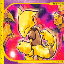

In [ ]:
img

In [ ]:
name.capitalize()

'Bulbasaur'

In [ ]:

images = []
labels = []
# Define la ruta a la carpeta de imágenes
for poke in pokemons:
    name=poke['name']
    print(name)
    label=poke['id']
    #importamos imagenes de TCG
    data_dir=os.path.join(Data_path,name,'tcg')
    for filename in os.listdir(data_dir):
        img = tf.keras.preprocessing.image.load_img(
            os.path.join(data_dir, filename), target_size=(500, 500)
        )
        height = img.height
        width = img.width
        img=np.array(img)
        cropped_image = tf.image.crop_to_bounding_box(img, int(0.09*height), int(0.05*width), int(0.42*height), int(0.9*width))
        img = tf.image.resize(cropped_image, (64, 64))
        images.append(img)
        labels.append(name)
    #importamos el resto de imagenes
    data_dir=os.path.join(Data_path,name)
    for filename in os.listdir(data_dir):
        try:
            img = tf.keras.preprocessing.image.load_img(
            os.path.join(data_dir, filename), target_size=(64, 64))
        except:

            pass
        img=np.array(img)
        images.append(img)
        labels.append(name)
    Name=name.capitalize()
    data_dir=os.path.join(Pk_data_path,Name)
    try:
        for filename in os.listdir(data_dir):

              img = tf.keras.preprocessing.image.load_img(
              os.path.join(data_dir, filename), target_size=(64, 64))
              img=np.array(img)
              images.append(img)
              labels.append(name)

    except:
        print(f'fail {name}/{Name}')
        pass


bulbasaur
ivysaur
venusaur
charmander
charmeleon
charizard
squirtle
wartortle
blastoise
caterpie
metapod
butterfree
weedle
kakuna
beedrill
pidgey
pidgeotto
pidgeot
rattata
raticate
spearow
fearow
ekans
arbok
pikachu
raichu
sandshrew
sandslash
nidoran-f
fail nidoran-f/Nidoran-f
nidorina
nidoqueen
nidoran-m
fail nidoran-m/Nidoran-m
nidorino
nidoking
clefairy
clefable
vulpix
ninetales
jigglypuff
wigglytuff
zubat
golbat
oddish
gloom
vileplume
paras
parasect
venonat
venomoth
diglett
dugtrio
meowth
persian
psyduck
golduck
mankey
primeape
growlithe
arcanine
poliwag
poliwhirl
poliwrath
abra
kadabra
alakazam
machop
machoke
machamp
bellsprout
weepinbell
victreebel
tentacool
tentacruel
geodude
graveler
golem
ponyta
rapidash
slowpoke
slowbro
magnemite
magneton
farfetchd
doduo
dodrio
seel
dewgong
grimer
muk
shellder
cloyster
gastly
haunter
gengar
onix
drowzee
hypno
krabby
kingler
voltorb
electrode
exeggcute
exeggutor
cubone
marowak
hitmonlee
hitmonchan
lickitung
koffing
weezing
rhyhorn
rhydon
chans

In [ ]:
np.save('/content/drive/MyDrive/Pk_classification/imglst.npy',images)

In [ ]:
np.save('/content/drive/MyDrive/Pk_classification/lbllst.npy',labels)

In [ ]:
pokemons=np.load('/content/drive/MyDrive/Pk_classification/pkmlst.npy',allow_pickle=True)
images=np.load('/content/drive/MyDrive/Pk_classification/imglst.npy',allow_pickle=True)
labels=np.load('/content/drive/MyDrive/Pk_classification/lbllst.npy',allow_pickle=True)

In [ ]:
print(len(images))
print(len(labels))

11992
11992


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.2, random_state=151)

In [ ]:
unique_labels=np.unique(labels)

print(unique_labels)

['abra' 'aerodactyl' 'alakazam' 'arbok' 'arcanine' 'articuno' 'beedrill'
 'bellsprout' 'blastoise' 'bulbasaur' 'butterfree' 'caterpie' 'chansey'
 'charizard' 'charmander' 'charmeleon' 'clefable' 'clefairy' 'cloyster'
 'cubone' 'dewgong' 'diglett' 'ditto' 'dodrio' 'doduo' 'dragonair'
 'dragonite' 'dratini' 'drowzee' 'dugtrio' 'eevee' 'ekans' 'electabuzz'
 'electrode' 'exeggcute' 'exeggutor' 'farfetchd' 'fearow' 'flareon'
 'gastly' 'gengar' 'geodude' 'gloom' 'golbat' 'goldeen' 'golduck' 'golem'
 'graveler' 'grimer' 'growlithe' 'gyarados' 'haunter' 'hitmonchan'
 'hitmonlee' 'horsea' 'hypno' 'ivysaur' 'jigglypuff' 'jolteon' 'jynx'
 'kabuto' 'kabutops' 'kadabra' 'kakuna' 'kangaskhan' 'kingler' 'koffing'
 'krabby' 'lapras' 'lickitung' 'machamp' 'machoke' 'machop' 'magikarp'
 'magmar' 'magnemite' 'magneton' 'mankey' 'marowak' 'meowth' 'metapod'
 'mew' 'mewtwo' 'moltres' 'mr-mime' 'muk' 'nidoking' 'nidoqueen'
 'nidoran-f' 'nidoran-m' 'nidorina' 'nidorino' 'ninetales' 'oddish'
 'omanyte' 'omast

In [ ]:
np.save('/content/drive/MyDrive/Pk_classification/uqlbl.npy',unique_labels)

In [ ]:
unique_labels=np.load('/content/drive/MyDrive/Pk_classification/uqlbl.npy')

In [ ]:
len(unique_labels)

151

In [ ]:
print(len(X_train),len(X_test))

9593 2399


In [ ]:
unique_labels=np.unique(labels)
label_to_index = {label: index for index, label in enumerate(unique_labels)}
label_indices = [label_to_index[label] for label in y_train]
poke_train_labels = tf.keras.utils.to_categorical(label_indices, num_classes=len(unique_labels))
poke_train_labels.shape

(9593, 151)

In [ ]:
Poke_train_img=np.stack([ sample for sample in X_train])
Poke_train_img.shape

(9593, 64, 64, 3)

In [ ]:
Poke_train_img=Poke_train_img.astype('float32')
Poke_train_img/=255

In [ ]:
unique_labels=np.unique(labels)
label_to_index = {label: index for index, label in enumerate(unique_labels)}
label_indices = [label_to_index[label] for label in y_test]
poke_test_labels = tf.keras.utils.to_categorical(label_indices, num_classes=len(unique_labels))
poke_test_labels.shape

(2399, 151)

In [ ]:
Poke_test_img=np.stack([ sample for sample in X_test])
Poke_test_img.shape

(2399, 64, 64, 3)

In [ ]:
Poke_test_img=Poke_test_img.astype('float32')
Poke_test_img/=255

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import keras
import numpy as np
from tensorflow.keras.utils import to_categorical
from tensorflow import keras
from etils import epath
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
Kanto_model=tf.keras.models.load_model(export_path_h5)
Kanto_model

In [ ]:
keras.backend.clear_session()

In [ ]:
Kanto_model = keras.Sequential([
    keras.layers.Conv2D(filters=12, kernel_size=5, activation="relu",input_shape=(64,64,3)),
    keras.layers.MaxPool2D(pool_size=(2,2)),
    keras.layers.Conv2D(filters=30, kernel_size=3, activation="relu"),
    keras.layers.MaxPool2D(pool_size=(2,2)),
    keras.layers.Flatten(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(200,activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(151,activation="softmax")
])

In [ ]:
Kanto_model.compile(
    optimizer = "adam",
    loss = "categorical_crossentropy",
    metrics = ["accuracy"]
)

In [ ]:
history=Kanto_model.fit(
    x = Poke_train_img,
    y = poke_train_labels,
    batch_size = 32,
    epochs = 30,
    validation_split = 0.2
)

Epoch 1/30
240/240 [==============================] - 40s 161ms/step - loss: 4.9272 - accuracy: 0.0143 - val_loss: 4.5952 - val_accuracy: 0.0412
Epoch 2/30
240/240 [==============================] - 34s 143ms/step - loss: 4.3713 - accuracy: 0.0601 - val_loss: 3.8643 - val_accuracy: 0.1282
Epoch 3/30
240/240 [==============================] - 35s 146ms/step - loss: 3.7843 - accuracy: 0.1405 - val_loss: 3.3855 - val_accuracy: 0.2376
Epoch 4/30
240/240 [==============================] - 34s 143ms/step - loss: 3.2947 - accuracy: 0.2191 - val_loss: 3.1342 - val_accuracy: 0.2918
Epoch 5/30
240/240 [==============================] - 35s 147ms/step - loss: 2.8723 - accuracy: 0.2961 - val_loss: 2.8999 - val_accuracy: 0.3356
Epoch 6/30
240/240 [==============================] - 34s 142ms/step - loss: 2.5821 - accuracy: 0.3593 - val_loss: 2.7447 - val_accuracy: 0.3700
Epoch 7/30
240/240 [==============================] - 34s 142ms/step - loss: 2.2877 - accuracy: 0.4132 - val_loss: 2.5983 - val_ac

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 60, 60, 12)        912       
                                                                 
 max_pooling2d (MaxPooling2  (None, 30, 30, 12)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 28, 28, 30)        3270      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 14, 14, 30)        0         
 g2D)                                                            
                                                                 
 flatten (Flatten)           (None, 5880)              0         
                                                                 
 dropout (Dropout)           (None, 5880)              0

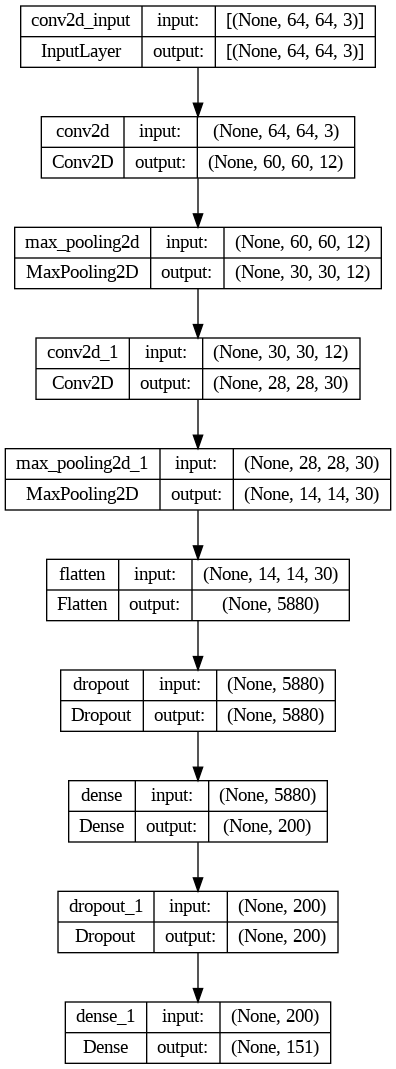

In [ ]:
Kanto_model.summary()
keras.utils.plot_model(Kanto_model, show_shapes=True)

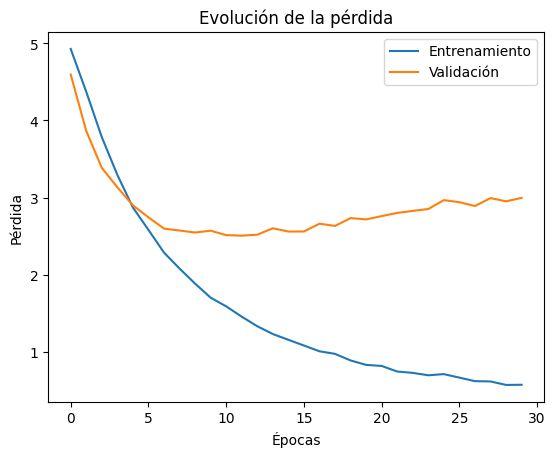

In [ ]:
import matplotlib.pyplot as plt

# Obtener los datos de entrenamiento y validación
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

# Graficar la pérdida de entrenamiento
plt.plot(train_loss, label="Entrenamiento")
plt.plot(val_loss, label="Validación")
plt.title("Evolución de la pérdida")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.legend()
plt.show()

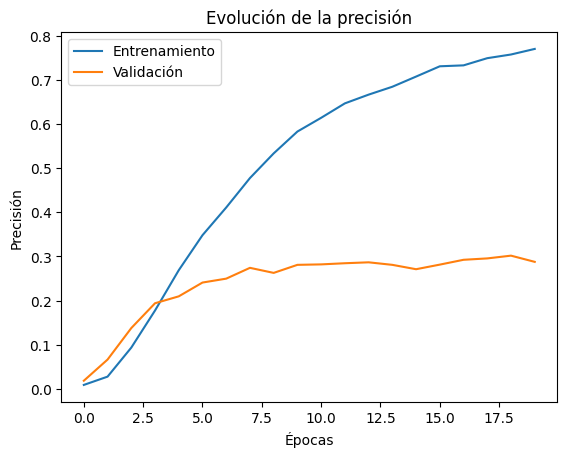

In [ ]:
# Obtener los datos de entrenamiento y validación
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

# Graficar la precisión de entrenamiento
plt.plot(train_accuracy, label="Entrenamiento")
plt.plot(val_accuracy, label="Validación")
plt.title("Evolución de la precisión")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.legend()
plt.show()


In [ ]:
Kanto_model.evaluate(
    x=Poke_test_img,
    y=poke_test_labels
)

75/75 [==============================] - 3s 33ms/step - loss: 2.9724 - accuracy: 0.4606


[2.9724323749542236, 0.4606086015701294]

In [ ]:
import random

In [ ]:
indices_aleatorios = random.sample(range(len(Poke_test_img)), 36)
indices_aleatorios

[1713,
 1445,
 1695,
 117,
 227,
 2351,
 1747,
 311,
 1677,
 2022,
 1877,
 35,
 1632,
 1964,
 2056,
 1728,
 1356,
 2204,
 1505,
 529,
 1237,
 269,
 1760,
 188,
 1431,
 348,
 2279,
 752,
 189,
 557,
 212,
 1426,
 1522,
 150,
 2007,
 1224]

In [ ]:
predicciones = Kanto_model.predict(Poke_test_img)


75/75 [==============================] - 7s 87ms/step


In [ ]:
predicciones

array([[6.8887173e-21, 7.0277381e-16, 3.4179343e-30, ..., 5.7289606e-13,
        6.4056249e-29, 1.7620435e-13],
       [1.0299109e-15, 3.3649910e-06, 2.4434093e-15, ..., 1.6486741e-11,
        2.3103120e-16, 1.8307192e-05],
       [6.5252441e-04, 7.5498130e-03, 1.4748909e-04, ..., 8.4518772e-03,
        9.0839130e-05, 7.4844654e-03],
       ...,
       [3.3392105e-09, 2.9195542e-04, 7.3721216e-09, ..., 1.8922979e-03,
        4.2277261e-08, 1.1378268e-05],
       [3.3780286e-06, 1.9215250e-02, 1.8512513e-07, ..., 8.0418732e-04,
        4.8385436e-06, 1.2209408e-04],
       [5.6924076e-08, 7.4866312e-03, 3.7892610e-06, ..., 1.4676530e-08,
        3.1177353e-07, 8.6644737e-05]], dtype=float32)

In [ ]:
unique_labels

array(['abra', 'aerodactyl', 'alakazam', 'arbok', 'arcanine', 'articuno',
       'beedrill', 'bellsprout', 'blastoise', 'bulbasaur', 'butterfree',
       'caterpie', 'chansey', 'charizard', 'charmander', 'charmeleon',
       'clefable', 'clefairy', 'cloyster', 'cubone', 'dewgong', 'diglett',
       'ditto', 'dodrio', 'doduo', 'dragonair', 'dragonite', 'dratini',
       'drowzee', 'dugtrio', 'eevee', 'ekans', 'electabuzz', 'electrode',
       'exeggcute', 'exeggutor', 'farfetchd', 'fearow', 'flareon',
       'gastly', 'gengar', 'geodude', 'gloom', 'golbat', 'goldeen',
       'golduck', 'golem', 'graveler', 'grimer', 'growlithe', 'gyarados',
       'haunter', 'hitmonchan', 'hitmonlee', 'horsea', 'hypno', 'ivysaur',
       'jigglypuff', 'jolteon', 'jynx', 'kabuto', 'kabutops', 'kadabra',
       'kakuna', 'kangaskhan', 'kingler', 'koffing', 'krabby', 'lapras',
       'lickitung', 'machamp', 'machoke', 'machop', 'magikarp', 'magmar',
       'magnemite', 'magneton', 'mankey', 'marowak', 'meo

In [ ]:
sample_img=[]
sample_lbl=[]
Predx=[]

for index in indices_aleatorios:
    Pred=predicciones[index].argmax()
    smp_img=tf.keras.utils.array_to_img(Poke_test_img[index])
    smp_lbl=poke_test_labels[index].argmax()
    sample_img.append(smp_img)
    sample_lbl.append(smp_lbl)
    Predx.append(Pred)

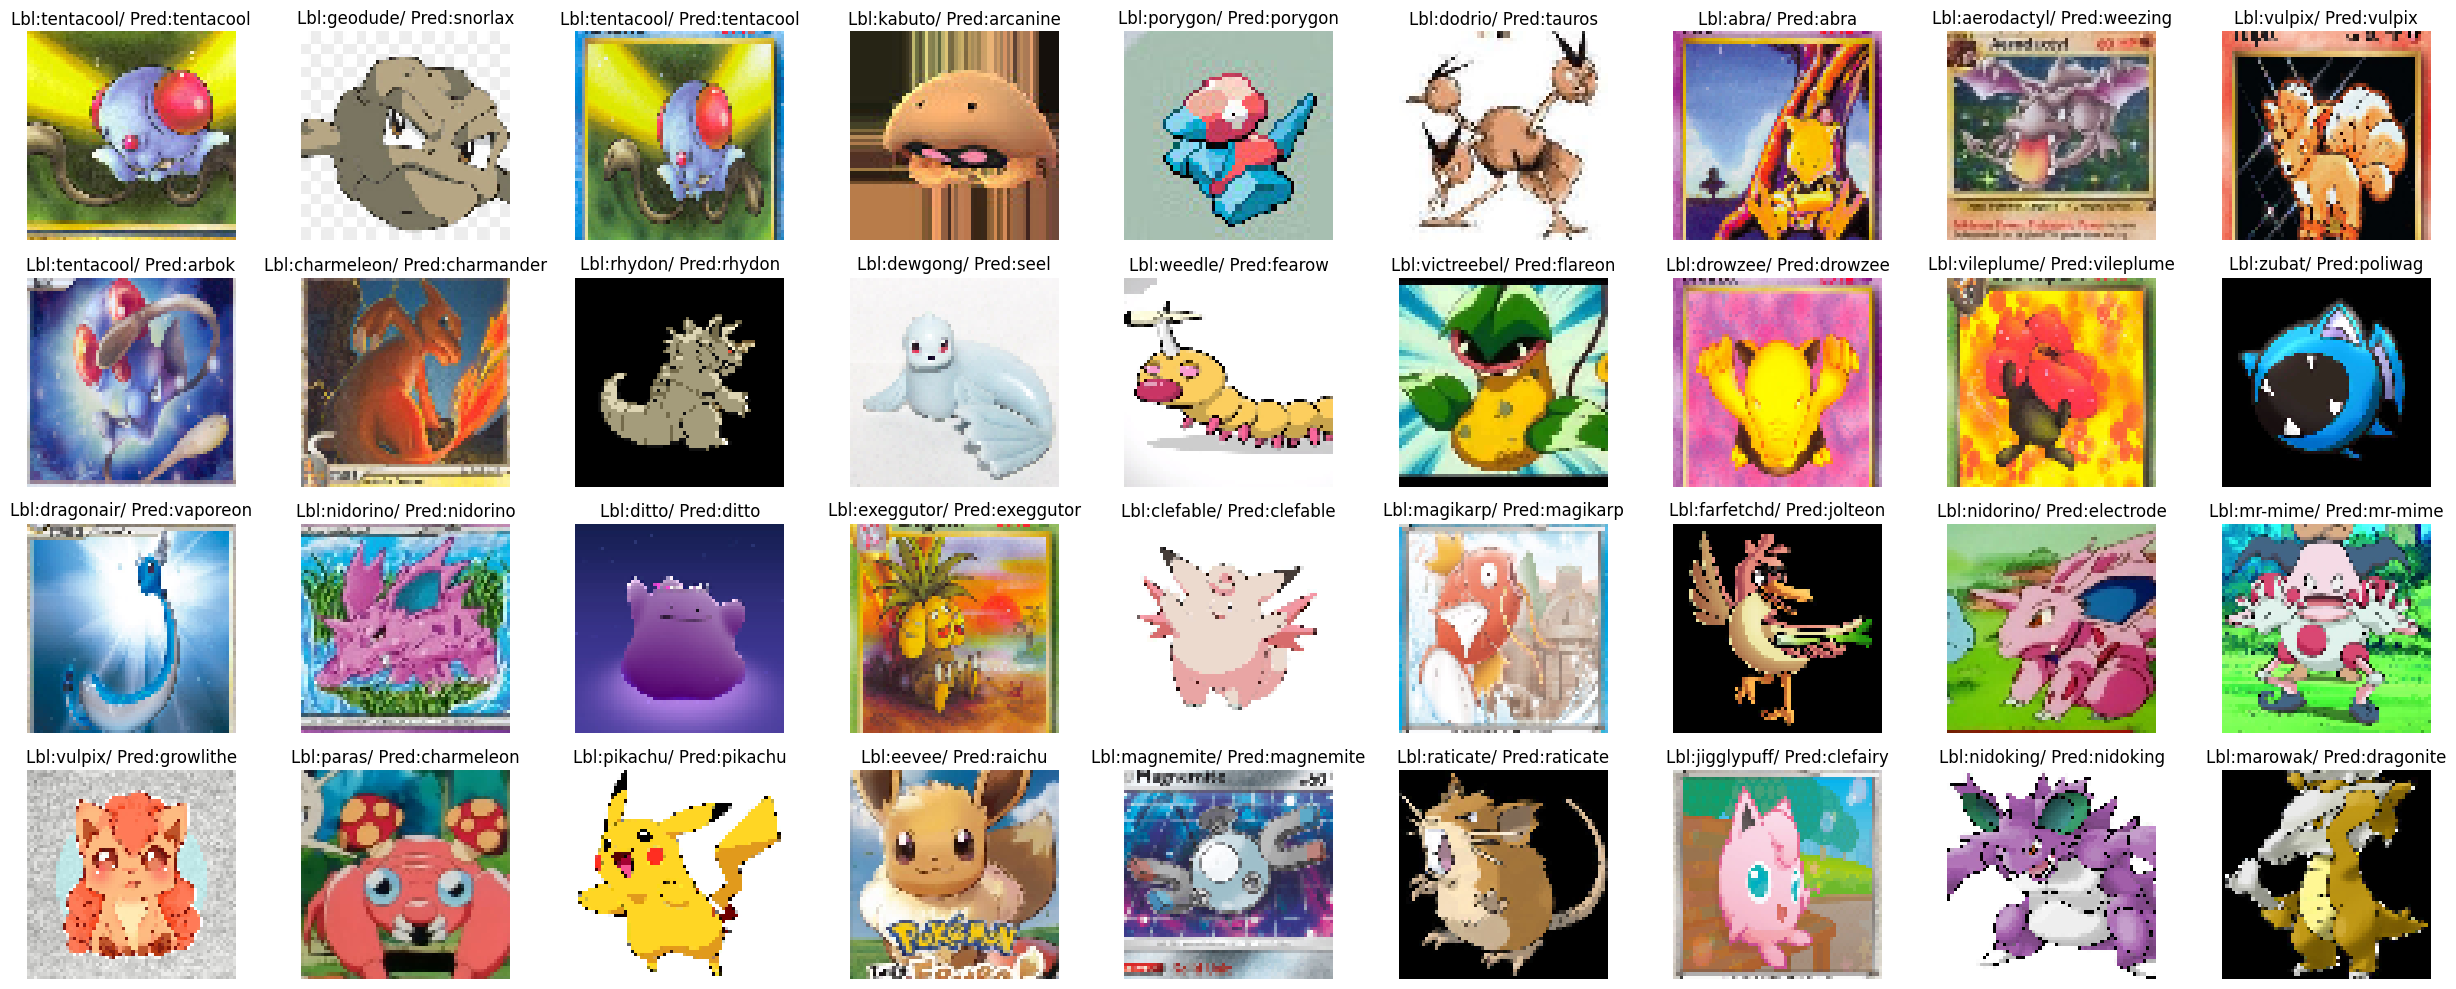

In [ ]:
fig, axs = plt.subplots(4,9, figsize=(25, 10))

# Recorrer las primeras 36 imágenes y etiquetas y trazarlas en los subgráficos
for i in range(36):
    row = i // 9
    col = i % 9
    axs[row, col].imshow(sample_img[i])
    axs[row, col].set_title('Lbl:{}/ Pred:{}'.format(unique_labels[sample_lbl[i]],unique_labels[Predx[i]]))
for ax in axs.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import tempfile
import os


In [ ]:
MODEL_DIR=tempfile.gettempdir()
version=1
export_path=os.path.join(MODEL_DIR,str(version))
print(export_path)


/tmp/1


In [ ]:
version=1
directorio='/content/drive/MyDrive/Pk_classification/Modelos'
nombre='kanto_classifier.h5'
export_path_h5=os.path.join(directorio,str(version),nombre)
#Kanto_model.save(filepath=export_path_h5)




In [ ]:
KCL.save('/content/drive/MyDrive/Pk_classification/Modelos/3/KantoModel.h5')

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [ ]:
tf.keras.models.save_model(
    Kanto_model,
    export_path,
    overwrite=True,
    include_optimizer=True
)

In [ ]:
! ls -l {export_path}

total 200
drwxr-xr-x 2 root root   4096 Nov  9 05:26 assets
-rw-r--r-- 1 root root     56 Nov  9 05:27 fingerprint.pb
-rw-r--r-- 1 root root  17765 Nov  9 05:27 keras_metadata.pb
-rw-r--r-- 1 root root 171826 Nov  9 05:27 saved_model.pb
drwxr-xr-x 2 root root   4096 Nov  9 05:27 variables


In [ ]:
! saved_model_cli show --dir {export_path}

2023-11-09 05:30:28.101488: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
The given SavedModel contains the following tag-sets:
'serve'


In [ ]:
# Instalar algunos paquetes de este servidor

# Vamos a validar si esta ejecución se esta realizando en SUDO
import sys
if "google.colab" not in sys.modules:
  SUDO_IF_NEEDED = "sudo"
else:
  SUDO_IF_NEEDED = ""

!echo "deb http://storage.googleapis.com/tensorflow-serving-apt stable tensorflow-model-server tensorflow-model-server-universal" | {SUDO_IF_NEEDED} tee /etc/apt/sources.list.d/tensorflow-serving.list && \
curl https://storage.googleapis.com/tensorflow-serving-apt/tensorflow-serving.release.pub.gpg | {SUDO_IF_NEEDED} apt-key add -
!{SUDO_IF_NEEDED} apt update

deb http://storage.googleapis.com/tensorflow-serving-apt stable tensorflow-model-server tensorflow-model-server-universal
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0Warning: apt-key is deprecated. Manage keyring files in trusted.gpg.d instead (see apt-key(8)).
100  2943  100  2943    0     0  10482      0 --:--:-- --:--:-- --:--:-- 10473
OK
Get:1 http://storage.googleapis.com/tensorflow-serving-apt stable InRelease [3,026 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,626 B]
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Get:4 http://security.ubuntu.com/ubuntu jammy-security InRelease [110 kB]
Get:5 http://storage.googleapis.com/tensorflow-serving-apt stable/tensorflow-model-server-universal amd64 Packages [348 B]
Hit:

In [ ]:
!wget 'http://storage.googleapis.com/tensorflow-serving-apt/pool/tensorflow-model-server-2.8.0/t/tensorflow-model-server/tensorflow-model-server_2.8.0_all.deb'
!dpkg -i tensorflow-model-server_2.8.0_all.deb
!pip3 install tensorflow-serving-api==2.8.0

--2023-11-09 05:32:45--  http://storage.googleapis.com/tensorflow-serving-apt/pool/tensorflow-model-server-2.8.0/t/tensorflow-model-server/tensorflow-model-server_2.8.0_all.deb
Resolving storage.googleapis.com (storage.googleapis.com)... 142.250.1.207, 172.253.119.207, 108.177.121.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.250.1.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 340152790 (324M) [application/x-debian-package]
Saving to: ‘tensorflow-model-server_2.8.0_all.deb’

tensorflow-model-se 100%[===================>] 324.39M   116MB/s    in 2.8s    

2023-11-09 05:32:47 (116 MB/s) - ‘tensorflow-model-server_2.8.0_all.deb’ saved [340152790/340152790]

Selecting previously unselected package tensorflow-model-server.
(Reading database ... 120874 files and directories currently installed.)
Preparing to unpack tensorflow-model-server_2.8.0_all.deb ...
Unpacking tensorflow-model-server (2.8.0) ...
Setting up tensorflow-model-ser

In [ ]:
export_path

'/tmp/1'

In [ ]:
os.environ['MODEL_DIR']=MODEL_DIR



In [ ]:
%%bash --bg
nohup tensorflow_model_server \
  --rest_api_port=8200 \
  --model_name=poke_model \
  --model_base_path="${MODEL_DIR}" > server.log 2>&1

In [ ]:
!tail server.log

2023-11-09 05:36:47.545088: E external/org_tensorflow/tensorflow/core/grappler/optimizers/meta_optimizer.cc:828] tfg_optimizer{} failed: NOT_FOUND: Op type not registered 'DisableCopyOnRead' in binary running on 148e6018e953. Make sure the Op and Kernel are registered in the binary running in this process. Note that if you are loading a saved graph which used ops from tf.contrib, accessing (e.g.) `tf.contrib.resampler` should be done before importing the graph, as contrib ops are lazily registered when the module is first accessed.
	when importing GraphDef to MLIR module in GrapplerHook
2023-11-09 05:36:47.851629: E external/org_tensorflow/tensorflow/core/grappler/optimizers/meta_optimizer.cc:828] tfg_optimizer{} failed: NOT_FOUND: Op type not registered 'DisableCopyOnRead' in binary running on 148e6018e953. Make sure the Op and Kernel are registered in the binary running in this process. Note that if you are loading a saved graph which used ops from tf.contrib, accessing (e.g.) `tf.co

#CREAR CLIENTE

In [ ]:
pip install requests

In [ ]:
import json
import random
import requests

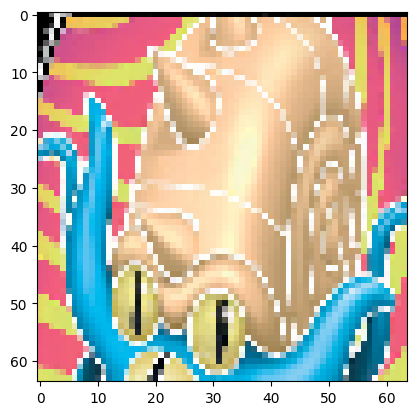

In [ ]:


rindex=random.randint(0,2398)

plt.figure()
plt.imshow(Poke_test_img[rindex])

Este pokémon es: electrode


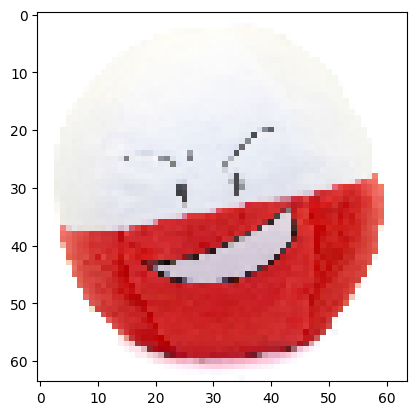

In [ ]:
rindex=random.randint(0,2398)
#Generar paquete
#Crear paquete y añadir imagen
plt.figure()
plt.imshow(Poke_test_img[rindex])

data=json.dumps(
    {
        "signature_name":"serving_default",
        "instances":Poke_test_img[rindex].reshape(1,64,64,3).tolist()

    }
)

#Header

header={
    "Content-type":"application/json"
}

respuesta=requests.post("http://localhost:8200/v1/models/poke_model:predict",headers=header,data=data)
indice_respuesta=np.argmax(json.loads(respuesta.text)['predictions'])
print(f'Este pokémon es: {unique_labels[indice_respuesta]}')